<!--
This copyright notice applies to this file only

SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: MIT

Permission is hereby granted, free of charge, to any person obtaining a
copy of this software and associated documentation files (the "Software"),
to deal in the Software without restriction, including without limitation
the rights to use, copy, modify, merge, publish, distribute, sublicense,
and/or sell copies of the Software, and to permit persons to whom the
Software is furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in
all copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
DEALINGS IN THE SOFTWARE.
-->


# Decoding Videos with PyNvVideoCodec SimpleDecoder

In this tutorial, we will learn how to decode a video using PyNvVideoCodec's SimpleDecoder class. We'll cover:
- Basic decoder setup and initialization
- Different methods to access video frames (index-based, slice, batch frames, etc.)
- How to fetch useful information about video like resolution, framerate using stream metadata.
- How to reconfigure same instance of decoder to decode video file of different resolution.

By the end, you will have a solid understanding of how to integrate SimpleDecoder into your own workflows for flexible and high-performance video decoding.

## Package Installation

First, let's install the required packages. We'll need:
- `matplotlib`: For displaying frames and detection results
- `requests`: For downloading sample video
- `numpy`: For array operations

Note: 
- PyNvVideoCodec should already be installed in your environment
- [CUDA toolkit](https://developer.nvidia.com/cuda-toolkit) should be installed

In [ ]:
%pip install matplotlib requests numpy

## Setup

Let's start by importing the necessary packages for getting started.

In [6]:

# Core video decoding
from PyNvVideoCodec import OutputColorType, SimpleDecoder

# Data handling and visualization
import numpy as np
import matplotlib.pyplot as plt
import torch

# Add parent directory to path to import from sibling utils folder
from pathlib import Path
import sys
parent_dir = str(Path('.').resolve().parent)
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from utils.Utils import convert_frames_to_torch

# CUDA initialization
import pycuda.driver as cuda
from pycuda.autoinit import context

# For downloading sample video
import requests

## Helper function for visualization

First, we'll define a utility function to display decoded frames in a grid layout.

In [7]:
def display_frames(frames, frame_indices=None, color_format=OutputColorType.RGB, num_cols=3):
    """Display frames from a torch tensor in a grid layout."""
    # Convert input to tensor format
    frames = [frames] if not isinstance(frames, list) else frames
    frames = convert_frames_to_torch(frames, color_format) if not isinstance(frames, torch.Tensor) else frames
    frames = frames.unsqueeze(0) if len(frames.shape) == 3 else frames
    
    # Setup display parameters
    num_frames = frames.shape[0]
    frame_indices = frame_indices if isinstance(frame_indices, list) else [frame_indices]
    num_rows = (num_frames + num_cols - 1) // num_cols
    
    # Create plot grid
    _, axes = plt.subplots(num_rows, num_cols, figsize=(15, 4*num_rows))
    axes = np.array([[axes]]) if num_rows == 1 and num_cols == 1 else axes.reshape(1, -1) if num_rows == 1 else axes
    plt.subplots_adjust(wspace=0.1, hspace=0)
    
    # Display frames
    for i in range(num_frames):
        frame_np = frames[i].cpu().numpy()
        if len(frame_np.shape) == 3 and frame_np.shape[0] == 3:  # Convert CHW to HWC
            frame_np = np.transpose(frame_np, (1, 2, 0))
        frame_np = frame_np / 255.0 if frame_np.max() > 1.0 else frame_np
        
        row, col = i // num_cols, i % num_cols
        axes[row, col].imshow(frame_np)
        axes[row, col].axis('off')
        axes[row, col].set_title(f'Frame {frame_indices[i]}', pad=0)
    
    # Hide empty subplots
    for i in range(num_frames, num_rows * num_cols):
        axes[i // num_cols, i % num_cols].axis('off')
    
    plt.show()

## Preparing the input video

For this tutorial, we'll use a sample video from [Pexels](https://www.pexels.com). First, let's create a helper function to download and save the video locally.

In [8]:
# Helper function to download and save a video
def download_video(url, save_path):
    """Downloads a video from URL and saves it locally."""
    print(f"Downloading video to {save_path}...")
    response = requests.get(url, stream=True)
    with open(save_path, 'wb') as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    print("Download complete!")
    return save_path

Now let's download our sample video.

In [9]:
# Download a 2.5K resolution video at 25fps
video_url = "https://videos.pexels.com/video-files/3196221/3196221-uhd_2560_1440_25fps.mp4"
input_video = download_video(video_url, "input1.mp4")

Download complete!


## 1. Creating the Decoder

The `SimpleDecoder` class provides GPU-accelerated video decoding with flexible configuration options. Let's create a decoder instance with the following settings:

- `enc_file_path`: Path to our input video file
- `gpu_id`: Which GPU to use (0 for the first GPU)
- `use_device_memory`: Keep decoded frames in GPU memory for faster processing
- `output_color_type`: Choose between RGB (HWC) or RGBP (CHW) format
- `need_scanned_stream_metadata`: Enable this to access frame-level information like keyframe locations



In [10]:
# Configure decoder settings
use_device_memory = True  # Keep frames in GPU memory
color_format = OutputColorType.RGB  # Use RGB interleaved format. OutputColorType.RGBP is also supported which is planar RGB format.

# Create our decoder instance
decoder = SimpleDecoder(
    enc_file_path=input_video,  # Path to the downloaded video
    gpu_id=0,                   # Use the first GPU
    use_device_memory=use_device_memory,
    output_color_type=color_format,
    need_scanned_stream_metadata=True  # Enable access to frame-level metadata
)

## 2. Understanding Video Stream Metadata

Before we start decoding frames, let's examine our video's properties. The `get_stream_metadata()` method provides essential information about the video stream such as:
- Resolution (width and height)
- Total number of frames
- Frame rate
- Duration

This information is useful for tasks like memory allocation or setting up processing pipelines.

In [11]:
# Get basic stream metadata
metadata = decoder.get_stream_metadata()

first_video_resolution = f"{metadata.width}x{metadata.height}"
# Display video properties in a readable format
print("Video Information:")
print(f"Resolution: {first_video_resolution}")
print(f"Frame Count: {metadata.num_frames}")
print(f"Frame Rate: {metadata.average_fps} fps")
print(f"Duration: {metadata.duration} seconds")

Video Information:
Resolution: 2560x1440
Frame Count: 385
Frame Rate: 25.0 fps
Duration: 15.36 seconds


## 3. Advanced Stream Information

The decoder can also provide more detailed information about the video stream through `get_scanned_stream_metadata()`. This includes:
- Key frame locations (I-frames)
- Presentation timestamps (PTS)
- Decode timestamps (DTS)
- Packet sizes

Note: This detailed metadata is only available because we set `need_scanned_stream_metadata=True` during decoder initialization.

In [12]:
# Get detailed stream metadata
scanned_metadata = decoder.get_scanned_stream_metadata()

# Display key frame information
key_frames = scanned_metadata.key_frame_indices
print(f"Number of key frames: {len(key_frames)}")
print(f"Key frame positions: {key_frames}")
print(f"Average GOP size: {key_frames[1] - key_frames[0]} frames")  # Distance between first two key frames

Number of key frames: 6
Key frame positions: [0, 76, 152, 228, 304, 380]
Average GOP size: 76 frames


## 4. Frame Access Methods

SimpleDecoder provides multiple ways to access frames:
- Single frame access using index
- Seek to specific frame
- Batch access
- Access by specific indices
- Slice access for multiple frames
- Get frame by time


Below is a visual overview of the different frame access methods provided by SimpleDecoder:

<img src="./SimpleDecoderAPIs.png" alt="SimpleDecoder Frame Access Methods" width="600"/>

Displaying first frame:


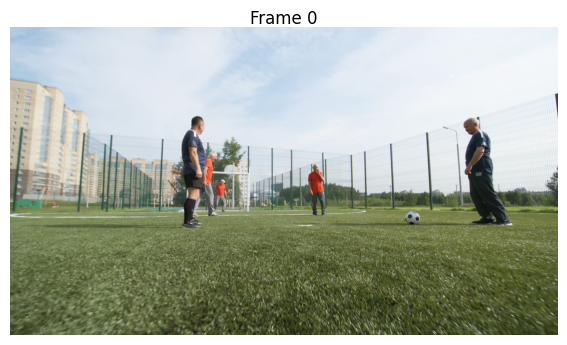

In [13]:
# 4.1 Single frame access using index
print("Displaying first frame:")
frame = decoder[0]
display_frames(frame, 0, color_format, num_cols=1)

Displaying frame at index 200:


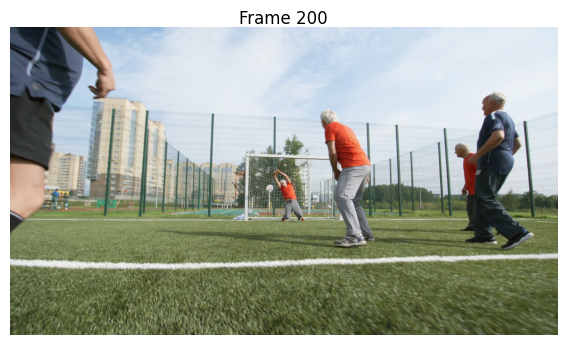

In [14]:
# 4.2 Seek to specific frame
frame_idx = 200
decoder.seek_to_index(frame_idx)
frame = decoder[frame_idx]
print(f"Displaying frame at index {frame_idx}:")
display_frames(frame, frame_idx, num_cols=1)

In [15]:
# 4.3 Batch access
print("Displaying batch of 9 frames:")
decoder.seek_to_index(160)
frames = decoder.get_batch_frames(9)
frame_indices = list(range(160, 160+9))
display_frames(frames, frame_indices)

Displaying batch of 9 frames:


Getting frames at specific indices:


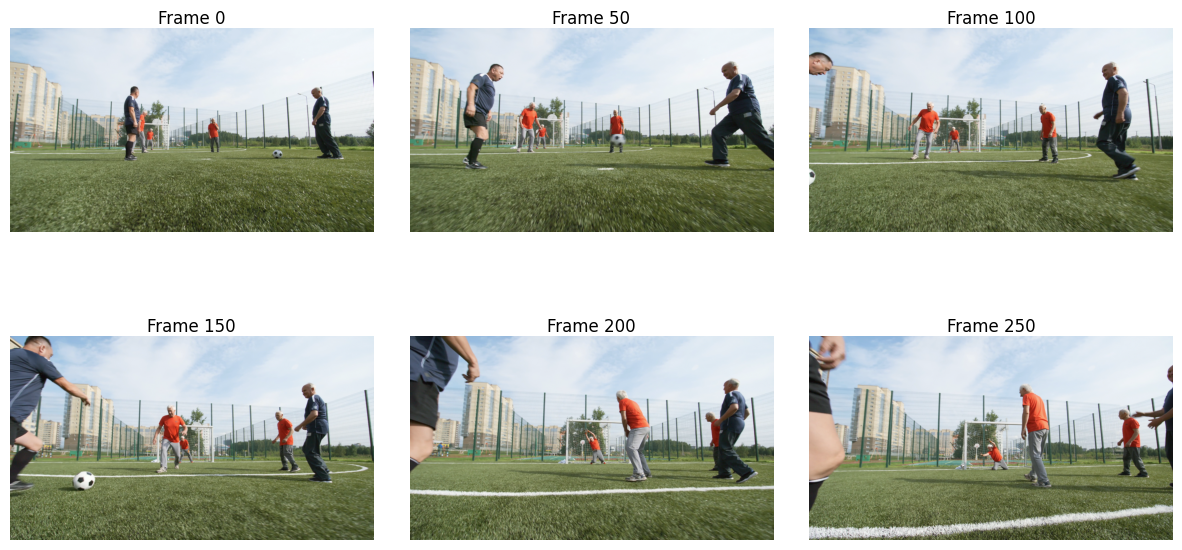

In [16]:
# 4.4 Access by specific indices
print("Getting frames at specific indices:")
frame_indices = [0, 50, 100, 150, 200, 250]
frames = decoder.get_batch_frames_by_index(frame_indices)
display_frames(frames, frame_indices)

Displaying frames 0,20,40,60,80,100 using slice:


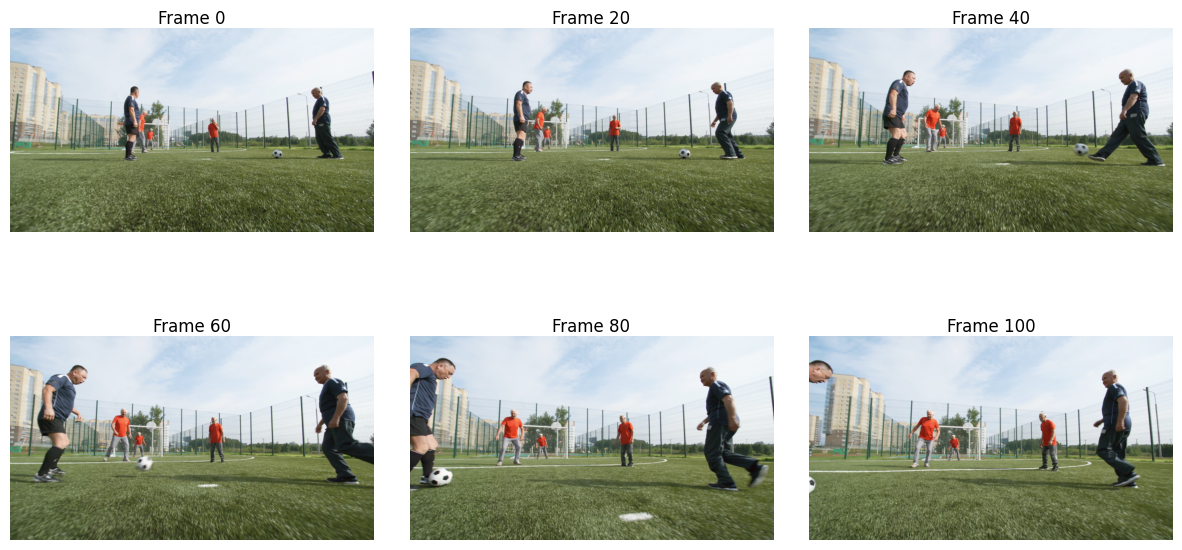

In [17]:
# 4.5 Slice access for multiple frames
print("Displaying frames 0,20,40,60,80,100 using slice:")
frames = decoder[0:120:20]
frame_indices = list(range(0,120,20))
display_frames(frames, frame_indices)

Frame at 5.0 seconds:


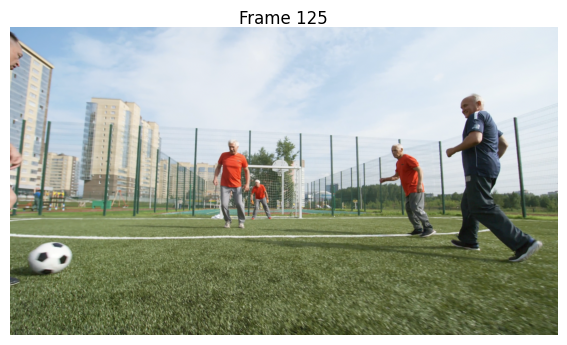

In [18]:
# 4.6 Get frame by time
time_in_seconds = 5.0
frame_idx = decoder.get_index_from_time_in_seconds(time_in_seconds)
frame = decoder[frame_idx]
print(f"Frame at {time_in_seconds} seconds:")
display_frames(frame, frame_idx, num_cols=1)

## 5. Reconfigure Decoder

In many deep learning applications, we need to process lots of short, low-resolution video clips. However, starting a new decoder for every video can take a lot of time. This extra setup work often slows things down and prevents full use of the GPU’s video decoding capability.
Decoder caching solves this problem by reusing the same decoder for multiple videos. Instead of creating a new decoder each time, the existing one is reconfigured and used again. This avoids the repeated setup cost, reduces delay, and improves decoding speed.
 
The diagram below illustrates the difference between traditional and cached decoding pipelines. In the traditional model, each video stream spawns a new decoder instance, introducing significant initialization overhead and limiting decoder throughput. With decoder caching, the system uses a lightweight reconfigure API to adapt an existing decoder for a new stream, avoiding full re-initialization

<img src="./ReconfigureDecoder.png" alt="Decoder Reconfigure vs Recreate" width="800"/>

Let's see how to reconfigure our existing decoder instance to process a different video:

Download complete!
New video resolution: 1920x1080. Note that the resolution of the earlier video was 2560x1440.


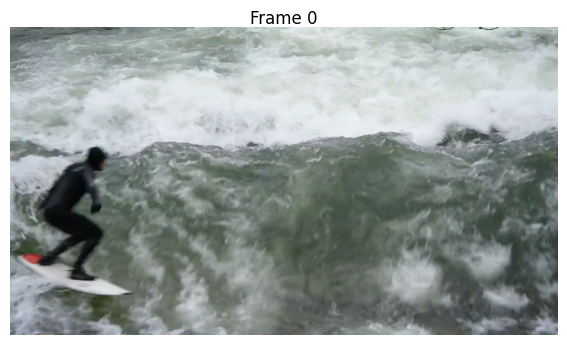

In [19]:
# Download a different video
video_url = "https://videos.pexels.com/video-files/856132/856132-hd_1920_1080_30fps.mp4"
input2_video = download_video(video_url, "input2.mp4")

# Reconfigure decoder with new video
decoder.reconfigure_decoder(input2_video)
second_video_resolution = f"{decoder.get_stream_metadata().width}x{decoder.get_stream_metadata().height}"

print(f"New video resolution: {second_video_resolution}. Note that the resolution of the earlier video was {first_video_resolution}.")
display_frames(decoder[0], 0, num_cols=1)